# Train and evaluate

## Import necessary libraries

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import os


## Load the panel data and divide into train and test sets, stratified by company

In [2]:
# ── Load the feature-engineered panel saved by the previous notebook ──
df_final_panel = pd.read_csv(os.path.join("data", "final_panel.csv"))

print(f"Loaded df_final_panel: {len(df_final_panel):,} rows x {len(df_final_panel.columns)} columns")


# Split must be by company — not by row — to prevent leakage.
# The same company's rows must appear entirely in train or
# entirely in test, never in both.
#
# Stratification ensures the ~11% bankruptcy rate is preserved
# in both train and test splits.
#
# Split: 80% train / 20% test

from sklearn.model_selection import train_test_split

company_labels = (
    df_final_panel
    .groupby("Company name Latin alphabet")["Bankrupt"]
    .first()
    .reset_index()
)

train_companies, test_companies = train_test_split(
    company_labels["Company name Latin alphabet"],
    test_size=0.2,
    random_state=42,
    stratify=company_labels["Bankrupt"]
)

train_companies = set(train_companies)
test_companies  = set(test_companies)

df_train = df_final_panel[
    df_final_panel["Company name Latin alphabet"].isin(train_companies)
].copy().reset_index(drop=True)

df_test = df_final_panel[
    df_final_panel["Company name Latin alphabet"].isin(test_companies)
].copy().reset_index(drop=True)

print(f"\nTrain set:")
print(f"  Rows:                 {len(df_train):,}")
print(f"  Unique companies:     {df_train['Company name Latin alphabet'].nunique():,}")
print(f"  Bankrupt companies:   {(df_train.groupby('Company name Latin alphabet')['Bankrupt'].first()==1).sum():,}")
print(f"  Active companies:     {(df_train.groupby('Company name Latin alphabet')['Bankrupt'].first()==0).sum():,}")

print(f"\nTest set:")
print(f"  Rows:                 {len(df_test):,}")
print(f"  Unique companies:     {df_test['Company name Latin alphabet'].nunique():,}")
print(f"  Bankrupt companies:   {(df_test.groupby('Company name Latin alphabet')['Bankrupt'].first()==1).sum():,}")
print(f"  Active companies:     {(df_test.groupby('Company name Latin alphabet')['Bankrupt'].first()==0).sum():,}")

overlap = train_companies & test_companies
print(f"\nCompany overlap between train and test: {len(overlap)} (must be 0)")

Loaded df_final_panel: 27,965 rows x 22 columns

Train set:
  Rows:                 22,314
  Unique companies:     8,097
  Bankrupt companies:   903
  Active companies:     7,194

Test set:
  Rows:                 5,651
  Unique companies:     2,025
  Bankrupt companies:   226
  Active companies:     1,799

Company overlap between train and test: 0 (must be 0)


## Address class imbalance

The sample differs from the real population in two ways, and each needs a different fix.

| Problem | Description | How it is handled |
|---|---|---|
| **Class imbalance** | About 8 active rows per bankrupt row in the training data | No reweighting (`scale_pos_weight = 1`): an 8:1 ratio is mild, and upweighting bankrupt rows would exaggerate a class that is already over-represented |
| **Sampling bias** | Every bankrupt company in the universe was exported, but only about 1 in 7 active companies (random sample). The sample is 11.15% bankrupt; the universe is 1.77% | Predicted probabilities are corrected to the universe base rate after training (see *Correct probabilities to universe base rate*) |

**Why the sample is not reweighted to 1.77% during training.** Reweighting the active rows up would reproduce the universe, but the model would then learn from only 1 bankruptcy per 55 companies. Training on the sample as it is and correcting the probabilities afterwards is the standard treatment for this kind of sample, where every case is kept and the controls are randomly sampled (case-control sampling; King & Zeng, 2001).

**What the correction affects.** Ranking metrics (ROC-AUC) are not affected by the sampling. Probabilities, precision and Average Precision are, because they depend on the base rate. These are reported both at the sample rate and re-estimated at the universe rate.

In [3]:
# ── Universe counts (hard-coded) ──────────────────────────────
# Taken from the Moody's Orbis search results screen, not from
# the exported files. The export was capped, so only a random
# sample of active companies was downloaded (9,100 of 62,916).
# All bankrupt companies were exported (1,136).
# Search criteria: Finland; status Active / Bankruptcy /
# Dissolved (bankruptcy); NACE sections K, O, P, Q, D, T, U
# excluded; revenue >= 200k EUR; total assets >= 100k EUR.
universe_total    = 64_052
universe_bankrupt =  1_136
universe_active   = universe_total - universe_bankrupt

# ── Sample counts (companies after cleaning) ──────────────────
company_label   = df_final_panel.groupby("Company name Latin alphabet")["Bankrupt"].first()
sample_active   = int((company_label == 0).sum())
sample_bankrupt = int((company_label == 1).sum())

# ── Sampling fractions ────────────────────────────────────────
# Share of each class in the universe that ended up in the sample.
# Used later to correct predicted probabilities to the universe.
sampling_frac_active   = sample_active   / universe_active     # ~0.14
sampling_frac_bankrupt = sample_bankrupt / universe_bankrupt   # ~0.99

universe_rate = universe_bankrupt / universe_total
sample_rate   = sample_bankrupt / (sample_active + sample_bankrupt)
train_row_rate = df_train["Bankrupt"].mean()

print(f"Universe (Moody's filtered search):")
print(f"  Active:               {universe_active:,}")
print(f"  Bankrupt:             {universe_bankrupt:,}")
print(f"  Bankruptcy rate:      {universe_rate:.2%}")

print(f"\nSample (after cleaning):")
print(f"  Active companies:     {sample_active:,}")
print(f"  Bankrupt companies:   {sample_bankrupt:,}")
print(f"  Bankruptcy rate:      {sample_rate:.2%}  (company level)")
print(f"  Train row-level rate: {train_row_rate:.2%}")
print(f"  Oversampling factor:  {sample_rate / universe_rate:.1f}×")

print(f"\nSampling fractions (sample / universe):")
print(f"  Active:               {sampling_frac_active:.4f}")
print(f"  Bankrupt:             {sampling_frac_bankrupt:.4f}")

# ── Class weighting ───────────────────────────────────────────
# No reweighting. The model is trained on the sample as it is;
# the sampling bias is corrected on the probabilities after
# training, not in the loss function.
scale_pos_weight = 1.0

print(f"\n→ scale_pos_weight = {scale_pos_weight:.1f} (no reweighting)")
print(f"→ Probabilities corrected to the {universe_rate:.2%} universe rate after training")

Universe (Moody's filtered search):
  Active:               62,916
  Bankrupt:             1,136
  Bankruptcy rate:      1.77%

Sample (after cleaning):
  Active companies:     8,993
  Bankrupt companies:   1,129
  Bankruptcy rate:      11.15%  (company level)
  Train row-level rate: 8.06%
  Oversampling factor:  6.3×

Sampling fractions (sample / universe):
  Active:               0.1429
  Bankrupt:             0.9938

→ scale_pos_weight = 1.0 (no reweighting)
→ Probabilities corrected to the 1.77% universe rate after training


## Prepare features and target variable for modeling

In [4]:
from sklearn.preprocessing import OneHotEncoder

# ── Numeric feature columns (explicit) ────────────────────────
# Listed explicitly so that a new column in final_panel.csv
# never silently becomes a model feature.
#
# Excluded on purpose:
#   Company name, Year of incorporation, NACE 4-digit code
#     — identifiers, or redundant with Company Age / NACE Section
#   Bankrupt — the target
#   Year — the label is static, so bankrupt companies' data stops
#     after failure and their rows cluster in early years
#     (bankrupt share 11.0% in 2022 vs 4.9% in 2024). Year would
#     learn when the data ends, not financial distress.
numeric_cols = [
    "Company Age",
    "Current assets",
    "Current liabilities",
    "P/L before tax",
    "Shareholders funds",
    "Total assets",
    "FE_total_liabilities",
    "FE_non_current_assets",
    "FE_debt_ratio",
    "FE_current_ratio",
    "FE_roa",
    "FE_negative_equity",
    "FE_negative_pl",
    "FE_assets_yoy_growth",
    "FE_equity_yoy_change",
]

missing = [col for col in numeric_cols if col not in df_train.columns]
assert not missing, f"Missing feature columns: {missing}"

# ── One-hot encode NACE Section ───────────────────────────────
# Fit on train only — prevents test set leakage.
# drop=None keeps all sections as explicit columns: tree models
# are not affected by the dummy-variable trap, and SHAP shows
# every industry instead of a hidden reference category.
ohe = OneHotEncoder(
    drop=None,
    sparse_output=False,
    handle_unknown="ignore",   # unseen section in test → all zeros
)

nace_train = ohe.fit_transform(df_train[["NACE Section"]])
nace_test  = ohe.transform(df_test[["NACE Section"]])

# Readable names for plots: "C - Manufacturing" → "Industry: Manufacturing"
nace_feature_names = [
    f"Industry: {section.split(' - ', 1)[1]}"
    for section in ohe.categories_[0]
]

# ── Build final feature matrices ──────────────────────────────
X_train = pd.concat(
    [df_train[numeric_cols],
     pd.DataFrame(nace_train, columns=nace_feature_names)],
    axis=1,
)
X_test = pd.concat(
    [df_test[numeric_cols],
     pd.DataFrame(nace_test, columns=nace_feature_names)],
    axis=1,
)

# Target vectors
y_train = df_train["Bankrupt"].values
y_test  = df_test["Bankrupt"].values

# ── Verify ────────────────────────────────────────────────────
# pd.concat aligns on index — a mismatch would add NaN rows
# silently instead of raising, so check row counts explicitly
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)

print(f"Feature matrices:")
print(f"  X_train: {X_train.shape}   X_test: {X_test.shape}")
print(f"  Features: {X_train.shape[1]} "
      f"({len(numeric_cols)} numeric/binary + {len(nace_feature_names)} industry)")
print(f"\nBankruptcy rate (rows):")
print(f"  Train: {y_train.mean():.2%}   Test: {y_test.mean():.2%}")

print(f"\nFeature columns:")
for i, col in enumerate(X_train.columns):
    print(f"  {i:>2}  {col}")

Feature matrices:
  X_train: (22314, 29)   X_test: (5651, 29)
  Features: 29 (15 numeric/binary + 14 industry)

Bankruptcy rate (rows):
  Train: 8.06%   Test: 8.42%

Feature columns:
   0  Company Age
   1  Current assets
   2  Current liabilities
   3  P/L before tax
   4  Shareholders funds
   5  Total assets
   6  FE_total_liabilities
   7  FE_non_current_assets
   8  FE_debt_ratio
   9  FE_current_ratio
  10  FE_roa
  11  FE_negative_equity
  12  FE_negative_pl
  13  FE_assets_yoy_growth
  14  FE_equity_yoy_change
  15  Industry: Agriculture, forestry, fishing
  16  Industry: Mining and quarrying
  17  Industry: Manufacturing
  18  Industry: Water supply, waste management
  19  Industry: Construction
  20  Industry: Wholesale and retail trade
  21  Industry: Transport and storage
  22  Industry: Accommodation and food service
  23  Industry: Information and communication
  24  Industry: Real estate
  25  Industry: Professional, scientific, technical
  26  Industry: Administrative a

## Define the model and cross-validate

In [5]:
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# ── Model definition ──────────────────────────────────────────
# Hyperparameters are common, well-tested starting values for
# gradient boosting on tabular data of this size (~22k rows,
# 29 features). They were set by hand, not tuned by search.
model = xgb.XGBClassifier(
    # Core parameters
    # Many small steps generalise better than a few large ones:
    # a low learning rate means each tree corrects only 5% of
    # the remaining error, and 500 trees give enough steps to
    # converge at that rate.
    n_estimators        = 500,
    learning_rate       = 0.05,
    # Shallow trees (max 4 splits deep) can still capture
    # interactions between up to 4 features — e.g. negative
    # equity AND losses AND low liquidity — without memorising
    # individual companies. Deeper trees overfit quickly on
    # ~2,000 bankrupt rows.
    max_depth           = 4,

    # Subsampling — each tree sees a random 80% of rows and 80%
    # of features. Trees become less correlated, so the ensemble
    # relies less on any single company or feature.
    subsample           = 0.8,
    colsample_bytree    = 0.8,

    # Regularization — penalties on the leaf weights (the score
    # each leaf adds to a prediction), keeping individual trees
    # from making extreme corrections.
    reg_alpha           = 0.1,   # L1 — light; can zero out weak leaves
    reg_lambda          = 1.0,   # L2 — XGBoost default; shrinks all leaves

    # Class imbalance — no reweighting (see Address class imbalance)
    scale_pos_weight    = scale_pos_weight,   # 1.0

    # Technical
    # n_jobs=1: parallelism is handled by cross_validate (one fold
    # per core) — nesting both would oversubscribe the CPU
    random_state        = 42,
    n_jobs              = 1,
)

print(f"XGBoost model defined:")
print(f"  n_estimators:        {model.n_estimators}")
print(f"  learning_rate:       {model.learning_rate}")
print(f"  max_depth:           {model.max_depth}")
print(f"  subsample:           {model.subsample}")
print(f"  colsample_bytree:    {model.colsample_bytree}")
print(f"  reg_alpha:           {model.reg_alpha}")
print(f"  reg_lambda:          {model.reg_lambda}")
print(f"  scale_pos_weight:    {model.scale_pos_weight:.1f}")

# ── Cross-validation setup ────────────────────────────────────
# StratifiedGroupKFold ensures:
#   - Each fold maintains class ratio (stratified)
#   - No company appears in both train and val fold (grouped)
#
# Groups = company name — one group per company
# All rows belonging to the same company go to the same fold

groups = df_train["Company name Latin alphabet"].values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Scoring metrics
# We report both ROC-AUC and Average Precision (PR-AUC)
# Average Precision is more informative for imbalanced data —
# ROC-AUC can look optimistic when negatives heavily dominate
scoring = {
    "roc_auc":         "roc_auc",
    "avg_precision":   "average_precision",
}

print(f"\nRunning 5-fold StratifiedGroupKFold cross-validation...")

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    groups=groups,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
)

# ── CV results ────────────────────────────────────────────────
print(f"\n{'='*58}")
print(f"  5-Fold Cross-Validation Results (train set)")
print(f"{'='*58}")
print(f"  {'Metric':<25} {'Train':>8}  {'Val':>8}  {'Std':>8}")
print(f"  {'-'*54}")

metrics = [
    ("ROC-AUC",          "roc_auc"),
    ("Avg Precision",    "avg_precision"),
]

for label, key in metrics:
    train_mean = cv_results[f"train_{key}"].mean()
    val_mean   = cv_results[f"test_{key}"].mean()
    val_std    = cv_results[f"test_{key}"].std()
    print(f"  {label:<25} {train_mean:>8.4f}  {val_mean:>8.4f}  {val_std:>8.4f}")

print(f"\n  Per-fold ROC-AUC:")
print(f"  {[f'{x:.4f}' for x in cv_results['test_roc_auc']]}")
print(f"\n  Per-fold Avg Precision:")
print(f"  {[f'{x:.4f}' for x in cv_results['test_avg_precision']]}")

XGBoost model defined:
  n_estimators:        500
  learning_rate:       0.05
  max_depth:           4
  subsample:           0.8
  colsample_bytree:    0.8
  reg_alpha:           0.1
  reg_lambda:          1.0
  scale_pos_weight:    1.0

Running 5-fold StratifiedGroupKFold cross-validation...

  5-Fold Cross-Validation Results (train set)
  Metric                       Train       Val       Std
  ------------------------------------------------------
  ROC-AUC                     0.9635    0.8561    0.0186
  Avg Precision               0.7501    0.3858    0.0465

  Per-fold ROC-AUC:
  ['0.8430', '0.8874', '0.8331', '0.8548', '0.8624']

  Per-fold Avg Precision:
  ['0.3361', '0.4639', '0.3497', '0.4108', '0.3684']


## Fit the final model on the full training set

In [6]:
# ── Fit final model on full training set ──────────────────────
# Cross-validation only estimates performance — cross_validate
# keeps no fitted model. The final model is therefore fitted on
# the complete training set, using all available information.
#
# This model is used by the Diagnostics, Evaluate on the test
# set and SHAP interpretability sections. Performance estimates
# come from the cross-validation above, not from this fit.

model.fit(X_train, y_train)

print(f"✓ Model fitted on full training set")
print(f"  Training rows:    {X_train.shape[0]:,}")
print(f"  Features:         {X_train.shape[1]:,}")
print(f"  Boosting rounds:  {model.n_estimators}")


✓ Model fitted on full training set
  Training rows:    22,314
  Features:         29
  Boosting rounds:  500


## Diagnostics

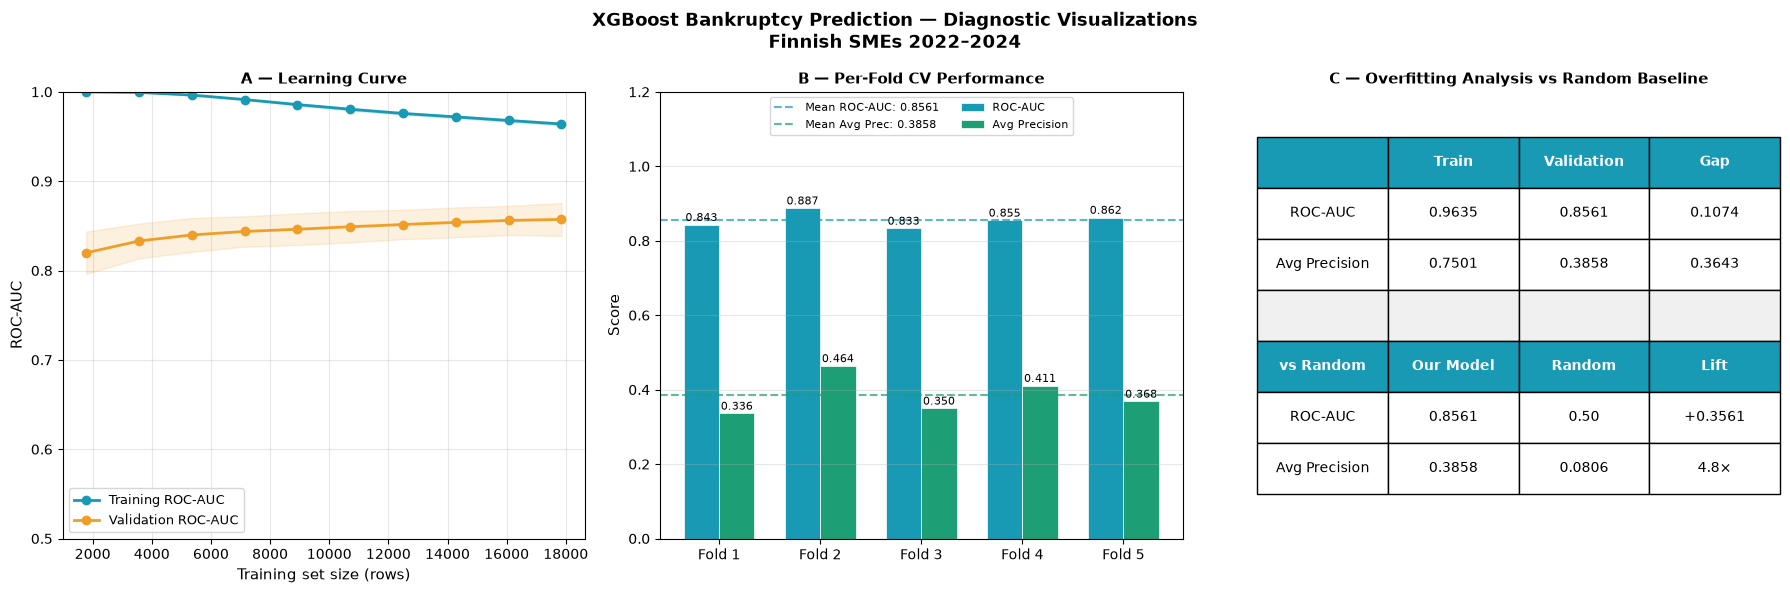

✓ Diagnostic plots saved to results/diagnostic_plots.png


In [7]:
# ── Diagnostics ───────────────────────────────────────────────
# Three diagnostic plots produced after fitting the final model:
#
#   A — Learning curve:
#       Shows ROC-AUC as training set size increases.
#       Confirms the model generalises beyond the training data
#       and that performance is not limited by data quantity.
#
#   B — Per-fold CV performance:
#       Bar chart of fold-level ROC-AUC and Average Precision.
#       Visually confirms stability across folds — no single
#       fold producing anomalous results.
#
#   C — Overfitting analysis table:
#       Quantifies train vs validation gap and the lift over
#       a random baseline.

import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

os.makedirs("results", exist_ok=True)

# ── A: Learning curve ─────────────────────────────────────────
# Reuses the same grouped CV strategy as the cross-validation
# above. train_sizes defines the fractions of training data to
# evaluate. shuffle=True draws each subset at random — df_train
# is sorted by company name, so without it the small subsets
# would contain only companies early in the alphabet.
# Shaded bands show ±1 standard deviation across folds.

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train, y_train,
    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42),
    groups=groups,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 10),
    shuffle=True,
    random_state=42,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'XGBoost Bankruptcy Prediction — Diagnostic Visualizations\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

# Learning curve plot
axes[0].plot(train_sizes, train_mean, 'o-', color='#189AB4',
             label='Training ROC-AUC', linewidth=2)
axes[0].fill_between(train_sizes,
                     train_mean - train_std,
                     train_mean + train_std,
                     alpha=0.15, color='#189AB4')
axes[0].plot(train_sizes, val_mean, 'o-', color='#EF9F27',
             label='Validation ROC-AUC', linewidth=2)
axes[0].fill_between(train_sizes,
                     val_mean - val_std,
                     val_mean + val_std,
                     alpha=0.15, color='#EF9F27')
axes[0].set_xlabel('Training set size (rows)', fontsize=11)
axes[0].set_ylabel('ROC-AUC', fontsize=11)
axes[0].set_title('A — Learning Curve', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0.5, 1.0)
axes[0].grid(True, alpha=0.3)

# ── B: Per-fold performance ───────────────────────────────────
folds    = [f'Fold {i+1}' for i in range(5)]
roc_vals = cv_results['test_roc_auc']
ap_vals  = cv_results['test_avg_precision']

x     = np.arange(len(folds))
width = 0.35

bars1 = axes[1].bar(x - width/2, roc_vals, width,
                    color='#189AB4', label='ROC-AUC',
                    edgecolor='white', linewidth=0.5)
bars2 = axes[1].bar(x + width/2, ap_vals, width,
                    color='#1D9E75', label='Avg Precision',
                    edgecolor='white', linewidth=0.5)

axes[1].axhline(y=roc_vals.mean(), color='#189AB4', linestyle='--',
                linewidth=1.5, alpha=0.7,
                label=f'Mean ROC-AUC: {roc_vals.mean():.4f}')
axes[1].axhline(y=ap_vals.mean(), color='#1D9E75', linestyle='--',
                linewidth=1.5, alpha=0.7,
                label=f'Mean Avg Prec: {ap_vals.mean():.4f}')

axes[1].set_xticks(x)
axes[1].set_xticklabels(folds)
axes[1].set_ylabel('Score', fontsize=11)
axes[1].set_title('B — Per-Fold CV Performance', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=8, loc='upper center', ncol=2)
axes[1].set_ylim(0, 1.2)
axes[1].grid(True, alpha=0.3, axis='y')

for bar in bars1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{bar.get_height():.3f}', ha='center', fontsize=8)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{bar.get_height():.3f}', ha='center', fontsize=8)

# ── C: Overfitting analysis ───────────────────────────────────
# Rendered as a formatted table inside the third subplot
gap_roc = cv_results['train_roc_auc'].mean() - cv_results['test_roc_auc'].mean()
gap_ap  = cv_results['train_avg_precision'].mean() - cv_results['test_avg_precision'].mean()
lift_random = cv_results['test_roc_auc'].mean() - 0.50
lift_ap     = cv_results['test_avg_precision'].mean() / y_train.mean()

table_data = [
    ['', 'Train', 'Validation', 'Gap'],
    ['ROC-AUC',
     f"{cv_results['train_roc_auc'].mean():.4f}",
     f"{cv_results['test_roc_auc'].mean():.4f}",
     f"{gap_roc:.4f}"],
    ['Avg Precision',
     f"{cv_results['train_avg_precision'].mean():.4f}",
     f"{cv_results['test_avg_precision'].mean():.4f}",
     f"{gap_ap:.4f}"],
    ['', '', '', ''],
    ['vs Random', 'Our Model', 'Random', 'Lift'],
    ['ROC-AUC',
     f"{cv_results['test_roc_auc'].mean():.4f}",
     '0.50',
     f"+{lift_random:.4f}"],
    ['Avg Precision',
     f"{cv_results['test_avg_precision'].mean():.4f}",
     f"{y_train.mean():.4f}",
     f"{lift_ap:.1f}×"],
]

axes[2].axis('off')
table = axes[2].table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc='center',
    loc='center',
    bbox=[0, 0.1, 1, 0.8]
)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Style header row
for j in range(4):
    table[0, j].set_facecolor('#189AB4')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Style separator rows (empty rows)
for j in range(4):
    table[3, j].set_facecolor('#f0f0f0')
    table[4, j].set_facecolor('#189AB4')
    table[4, j].set_text_props(color='white', fontweight='bold')

axes[2].set_title('C — Overfitting Analysis vs Random Baseline',
                  fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("results/diagnostic_plots.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"✓ Diagnostic plots saved to results/diagnostic_plots.png")


## Evaluate on the test set

Threshold chosen on training CV (max F1):
  Threshold:     0.2107
  F1 (train CV): 0.4208

Test set predictions:
  Rows:             5,651
  Mean probability: 0.0786   (actual test rate: 0.0842)

Test performance at threshold 0.2107:
  F1:         0.4344
  Precision:  0.3758
  Recall:     0.5147


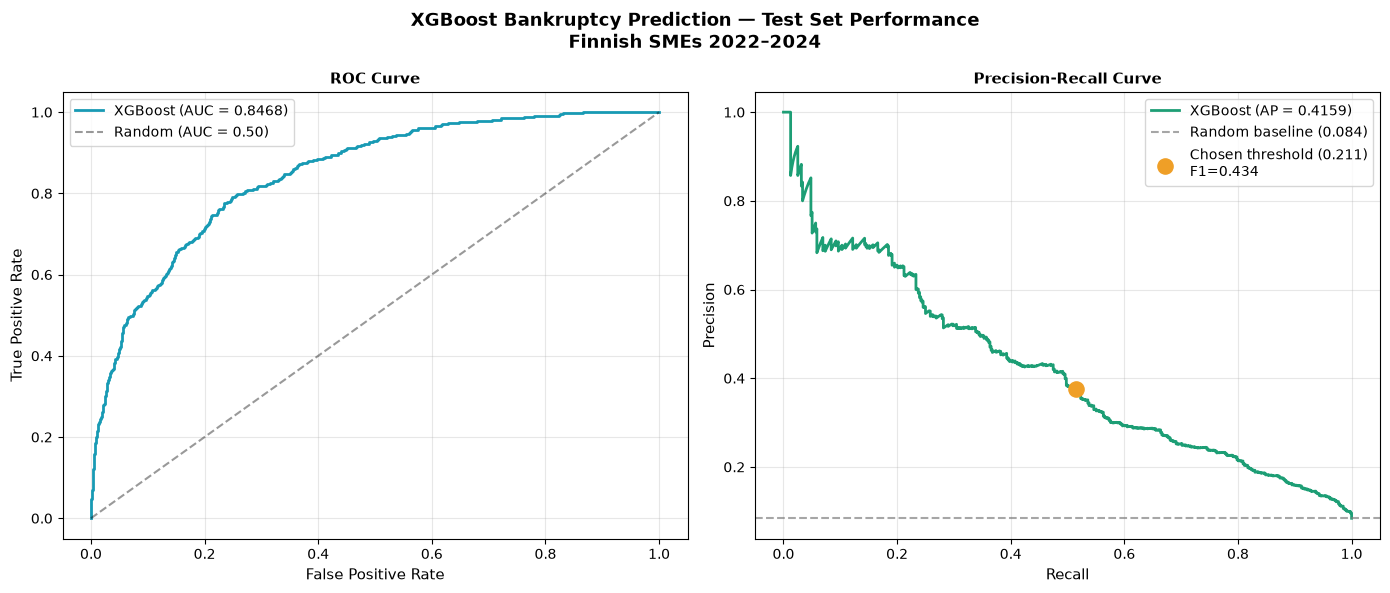

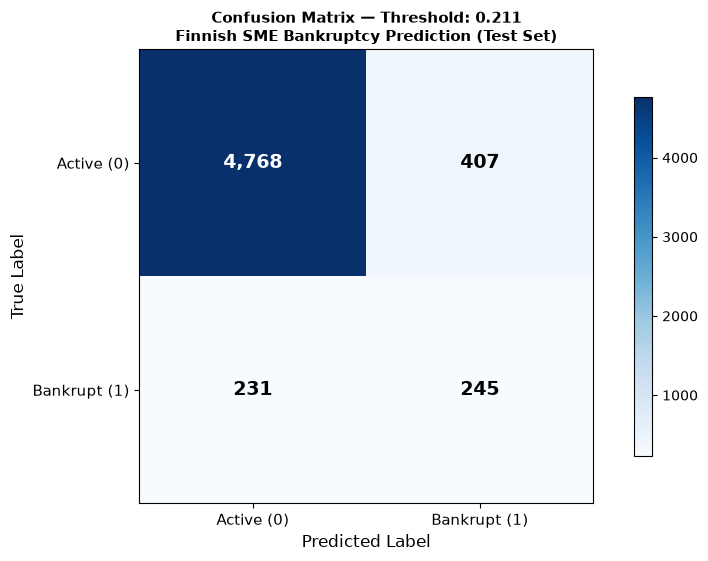


  Test Set Performance Summary
  Threshold (from training CV): 0.2107

  Metric                         Score     Benchmark
  ------------------------------------------------------
  ROC-AUC                       0.8468        0.5000 (random)
  Average Precision             0.4159        0.0842 (random)
  F1 Score                      0.4344             —
  Precision                     0.3758             —
  Recall                        0.5147             —

  Confusion matrix:
    True  Negatives (TN):  4,768  correctly identified active
    False Positives (FP):    407  active flagged as bankrupt
    False Negatives (FN):    231  bankruptcies missed
    True  Positives (TP):    245  bankruptcies correctly caught

  Classification report:
              precision    recall  f1-score   support

      Active     0.9538    0.9214    0.9373      5175
    Bankrupt     0.3758    0.5147    0.4344       476

    accuracy                         0.8871      5651
   macro avg     0.6648    0.

In [8]:
# ── Test set evaluation ───────────────────────────────────────
# Final evaluation on the held-out test set — 20% of companies
# never seen during training or cross-validation.
#
#   A — Choose the classification threshold on the TRAINING set
#       (out-of-fold CV predictions), so the test set is used
#       only for scoring, never for tuning
#   B — Predicted probabilities on the test set
#   C — ROC curve + Precision-Recall curve
#   D — Confusion matrix at the chosen threshold
#   E — Performance summary and classification report

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

# ── A: Threshold from out-of-fold training predictions ────────
# Each training row is predicted by a model that did not see its
# company (same grouped 5-fold CV as above). The threshold that
# maximises F1 on these predictions is then fixed and applied to
# the test set unchanged.
y_prob_oof = cross_val_predict(
    model, X_train, y_train,
    cv=cv, groups=groups,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

precisions_oof, recalls_oof, thresholds_oof = precision_recall_curve(y_train, y_prob_oof)
f1_oof = 2 * (precisions_oof[:-1] * recalls_oof[:-1]) / (
    precisions_oof[:-1] + recalls_oof[:-1] + 1e-9
)
optimal_threshold = thresholds_oof[np.argmax(f1_oof)]

print(f"Threshold chosen on training CV (max F1):")
print(f"  Threshold:     {optimal_threshold:.4f}")
print(f"  F1 (train CV): {f1_oof.max():.4f}")

# ── B: Test set predictions at the fixed threshold ────────────
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= optimal_threshold).astype(int)

optimal_f1        = f1_score(y_test, y_pred)
optimal_precision = precision_score(y_test, y_pred)
optimal_recall    = recall_score(y_test, y_pred)

print(f"\nTest set predictions:")
print(f"  Rows:             {len(y_prob):,}")
print(f"  Mean probability: {y_prob.mean():.4f}   "
      f"(actual test rate: {y_test.mean():.4f})")
print(f"\nTest performance at threshold {optimal_threshold:.4f}:")
print(f"  F1:         {optimal_f1:.4f}")
print(f"  Precision:  {optimal_precision:.4f}")
print(f"  Recall:     {optimal_recall:.4f}")

# ── C: ROC + Precision-Recall curves ─────────────────────────
precisions, recalls, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'XGBoost Bankruptcy Prediction — Test Set Performance\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc     = roc_auc_score(y_test, y_prob)

axes[0].plot(fpr, tpr, color='#189AB4', linewidth=2,
             label=f'XGBoost (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC = 0.50)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Precision-Recall curve
axes[1].plot(recalls, precisions, color='#1D9E75', linewidth=2,
             label=f'XGBoost (AP = {average_precision_score(y_test, y_prob):.4f})')
axes[1].axhline(y=y_test.mean(), color='gray', linestyle='--',
                alpha=0.7, label=f'Random baseline ({y_test.mean():.3f})')
axes[1].scatter(optimal_recall, optimal_precision,
                color='#EF9F27', s=120, zorder=5,
                label=f'Chosen threshold ({optimal_threshold:.3f})\n'
                      f'F1={optimal_f1:.3f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── D: Confusion matrix ───────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax, fraction=0.035, pad=0.08)

classes = ['Active (0)', 'Bankrupt (1)']
tick_marks = np.arange(len(classes))
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)
ax.set_xticklabels(classes, fontsize=11)
ax.set_yticklabels(classes, fontsize=11)

# Annotate cells
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i, j]:,}',
                ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > thresh else 'black',
                fontweight='bold')

ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title(
    f'Confusion Matrix — Threshold: {optimal_threshold:.3f}\n'
    f'Finnish SME Bankruptcy Prediction (Test Set)',
    fontsize=11, fontweight='bold'
)

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ── E: Final performance summary ─────────────────────────────
avg_precision = average_precision_score(y_test, y_prob)

print(f"\n{'='*58}")
print(f"  Test Set Performance Summary")
print(f"{'='*58}")
print(f"  Threshold (from training CV): {optimal_threshold:.4f}")
print(f"")
print(f"  {'Metric':<25} {'Score':>10}  {'Benchmark':>12}")
print(f"  {'-'*54}")
print(f"  {'ROC-AUC':<25} {roc_auc:>10.4f}  {0.5:>12.4f} (random)")
print(f"  {'Average Precision':<25} {avg_precision:>10.4f}  {y_test.mean():>12.4f} (random)")
print(f"  {'F1 Score':<25} {optimal_f1:>10.4f}  {'—':>12}")
print(f"  {'Precision':<25} {optimal_precision:>10.4f}  {'—':>12}")
print(f"  {'Recall':<25} {optimal_recall:>10.4f}  {'—':>12}")
print(f"")
print(f"  Confusion matrix:")
print(f"    True  Negatives (TN): {tn:>6,}  correctly identified active")
print(f"    False Positives (FP): {fp:>6,}  active flagged as bankrupt")
print(f"    False Negatives (FN): {fn:>6,}  bankruptcies missed")
print(f"    True  Positives (TP): {tp:>6,}  bankruptcies correctly caught")
print(f"")
print(f"  Classification report:")
print(classification_report(y_test, y_pred,
      target_names=["Active", "Bankrupt"], digits=4))

## Correct probabilities to universe base rate

The model was trained on a sample in which bankrupt companies are over-represented about 6.3× (11.15% vs 1.77%). Its probabilities therefore describe the **sample**, not the Finnish SME universe.

Because every bankrupt company was kept and active companies were sampled at random, the bias is known exactly and can be removed by rescaling the odds by the sampling fractions:

```
odds_sample   = p / (1 - p)
odds_universe = odds_sample × (sampling_frac_active / sampling_frac_bankrupt)
p_universe    = odds_universe / (1 + odds_universe)
```

`sampling_frac_active` is the share of active universe companies that ended up in the sample (about 0.14); `sampling_frac_bankrupt` is the same share for bankrupt companies (about 0.99).

The correction is monotonic, so it **does not change the ranking**: ROC-AUC and the set of companies flagged at a given cut-off stay the same. What changes is the interpretation:

- **Probabilities.** A company's corrected probability is its estimated chance of bankruptcy among Finnish SMEs, not within the sample.
- **Precision and Average Precision.** In the universe there are about 7× more active companies per bankrupt one, so each false positive counts about 7× more. These metrics are re-estimated by weighting each test row by the inverse of its sampling fraction.

Odds correction factor: 0.1438

Mean predicted probability:
  Sample level (raw model):    0.0786   actual test rate: 0.0842
  Universe level (corrected):  0.0123   universe rate:    0.0131
  (both row level; company-level universe rate is 0.0177)

  Test metrics: sample base rate vs universe base rate
  Metric                         Sample   Universe      Random
  ----------------------------------------------------------
  Bankruptcy rate (rows)         0.0842     0.0131            
  ROC-AUC                        0.8468     0.8468        0.50
  Average Precision              0.4159     0.1285      0.0131 (univ.)
  Precision @ threshold          0.3758     0.0797
  Recall @ threshold             0.5147     0.5147

  Threshold: 0.2107 (sample prob.) = 0.0370 (universe prob.)
  Recall is unchanged: it only involves bankrupt companies,
  which were sampled almost completely.


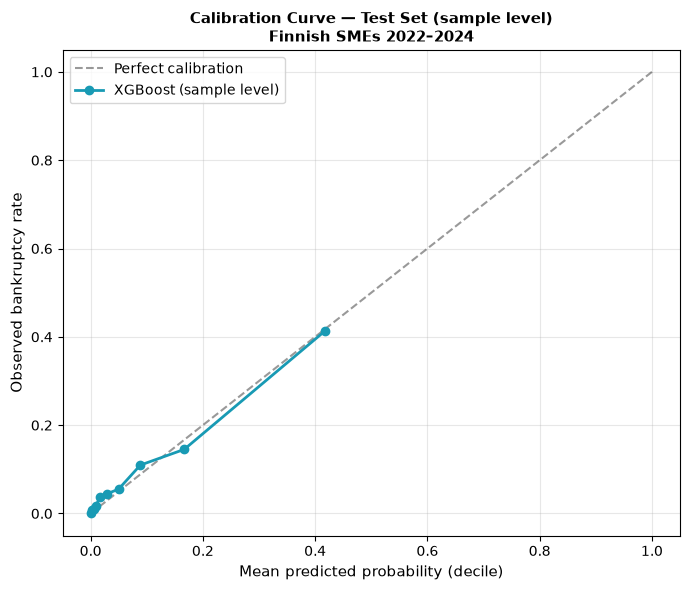

In [9]:
# ============================================================
# PROBABILITY CORRECTION TO UNIVERSE BASE RATE
# ============================================================
# Prior correction for case-control sampling: rescale the odds
# by the ratio of sampling fractions. Monotonic — rankings,
# ROC-AUC and flagged companies are unchanged.

from sklearn.calibration import calibration_curve

odds_factor = sampling_frac_active / sampling_frac_bankrupt

def to_universe_prob(p, factor=odds_factor):
    """Convert sample-level probabilities to universe-level."""
    p = np.clip(p, 1e-9, 1 - 1e-9)
    odds = p / (1 - p) * factor
    return odds / (1 + odds)

y_prob_universe = to_universe_prob(y_prob)

# ── A: Probability levels before and after ───────────────────
# Inverse sampling weights: how many universe companies each
# test row represents. Weighted means estimate universe values.
w_universe = np.where(y_test == 1,
                      1 / sampling_frac_bankrupt,
                      1 / sampling_frac_active)

# The model predicts company-years (rows), so checks must use the
# row-level rate. Bankrupt companies have fewer rows (their data
# stops after failure), so the row-level rate is lower than the
# company-level rate — in the sample and in the universe alike.
universe_row_rate = np.average(y_test, weights=w_universe)

print(f"Odds correction factor: {odds_factor:.4f}")
print(f"\nMean predicted probability:")
print(f"  Sample level (raw model):    {y_prob.mean():.4f}   "
      f"actual test rate: {y_test.mean():.4f}")
print(f"  Universe level (corrected):  "
      f"{np.average(y_prob_universe, weights=w_universe):.4f}   "
      f"universe rate:    {universe_row_rate:.4f}")
print(f"  (both row level; company-level universe rate is {universe_rate:.4f})")

# ── B: Metrics at sample vs universe base rate ────────────────
roc_sample = roc_auc_score(y_test, y_prob)
roc_univ   = roc_auc_score(y_test, y_prob, sample_weight=w_universe)
ap_sample  = average_precision_score(y_test, y_prob)
ap_univ    = average_precision_score(y_test, y_prob, sample_weight=w_universe)

# Precision at the chosen threshold — re-weighted to universe
tp_u = ((y_pred == 1) & (y_test == 1)) / sampling_frac_bankrupt
fp_u = ((y_pred == 1) & (y_test == 0)) / sampling_frac_active
precision_univ = tp_u.sum() / (tp_u.sum() + fp_u.sum())

print(f"\n{'='*62}")
print(f"  Test metrics: sample base rate vs universe base rate")
print(f"{'='*62}")
print(f"  {'Metric':<26} {'Sample':>10} {'Universe':>10}  {'Random':>10}")
print(f"  {'-'*58}")
print(f"  {'Bankruptcy rate (rows)':<26} {y_test.mean():>10.4f} {universe_row_rate:>10.4f}  {'':>10}")
print(f"  {'ROC-AUC':<26} {roc_sample:>10.4f} {roc_univ:>10.4f}  {0.5:>10.2f}")
print(f"  {'Average Precision':<26} {ap_sample:>10.4f} {ap_univ:>10.4f}  "
      f"{universe_row_rate:>10.4f} (univ.)")
print(f"  {'Precision @ threshold':<26} {optimal_precision:>10.4f} {precision_univ:>10.4f}")
print(f"  {'Recall @ threshold':<26} {optimal_recall:>10.4f} {optimal_recall:>10.4f}")
print(f"\n  Threshold: {optimal_threshold:.4f} (sample prob.) = "
      f"{to_universe_prob(optimal_threshold):.4f} (universe prob.)")
print(f"  Recall is unchanged: it only involves bankrupt companies,")
print(f"  which were sampled almost completely.")

# ── C: Calibration check (sample level) ───────────────────────
# With scale_pos_weight = 1 the raw probabilities should track
# observed bankruptcy rates in the sample. Points near the
# diagonal confirm this, so the universe correction rests on
# well-calibrated inputs.
frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Perfect calibration')
ax.plot(mean_pred, frac_pos, 'o-', color='#189AB4', linewidth=2,
        label='XGBoost (sample level)')
ax.set_xlabel('Mean predicted probability (decile)', fontsize=11)
ax.set_ylabel('Observed bankruptcy rate', fontsize=11)
ax.set_title('Calibration Curve — Test Set (sample level)\n'
             'Finnish SMEs 2022–2024', fontsize=11, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/calibration_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## SHAP interpretability

SHAP decomposes each prediction into a contribution from every feature. The values are on the model's raw **log-odds** scale and describe the sample-trained model.

The universe correction does not change them: on the log-odds scale it adds the same constant to every prediction, which shifts only the base value. Each feature's contribution, and the feature ranking, are identical at sample and universe level.

SHAP values computed:
  Shape: (5651, 29)
  (rows × features = 5,651 × 29)


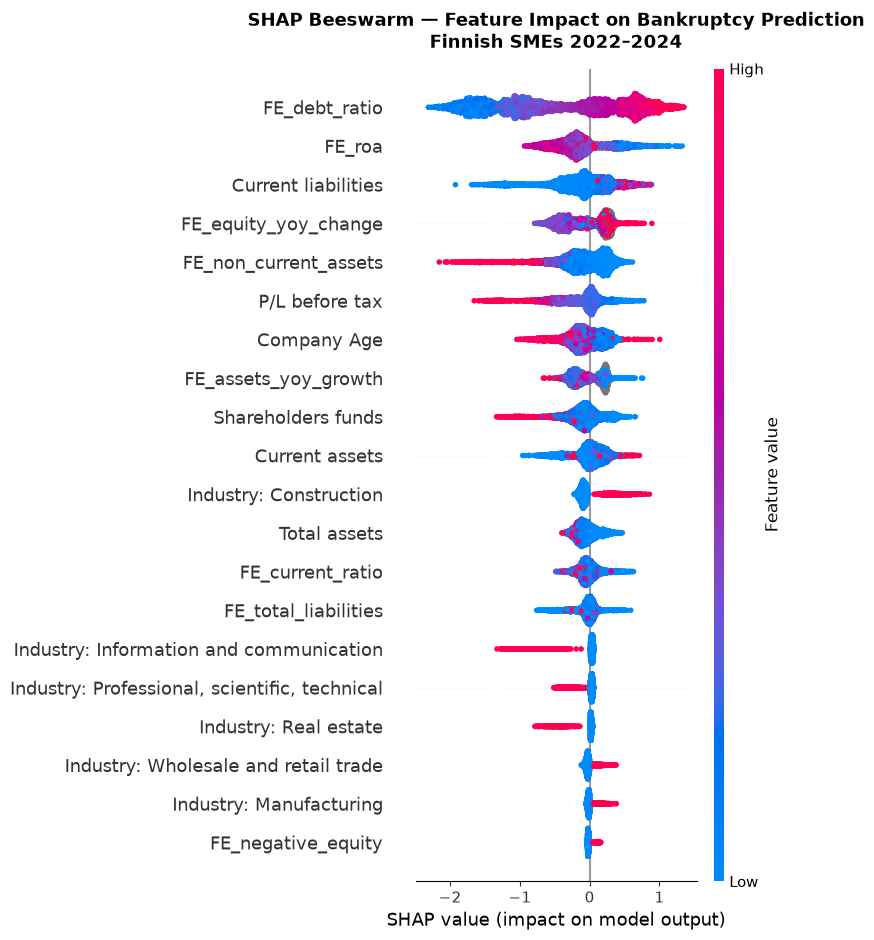

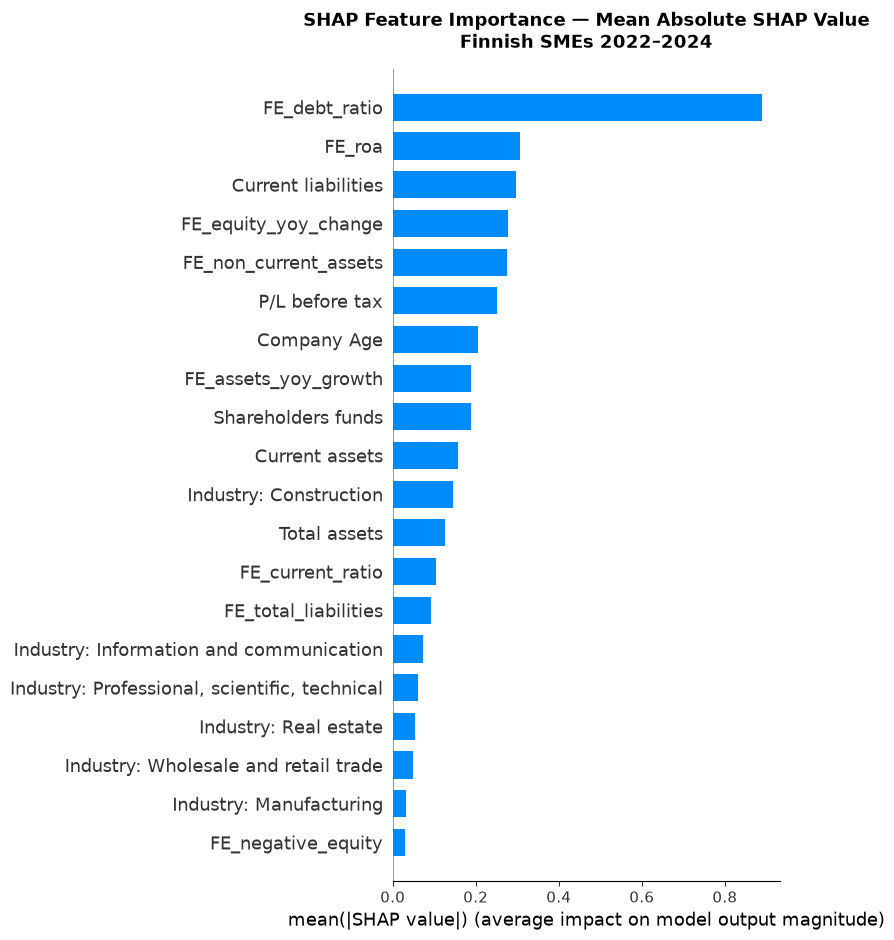

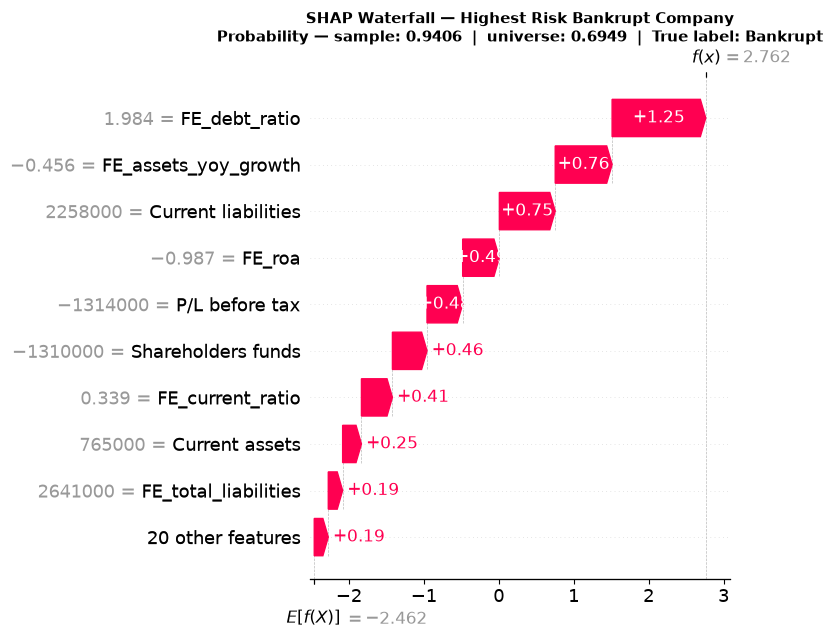

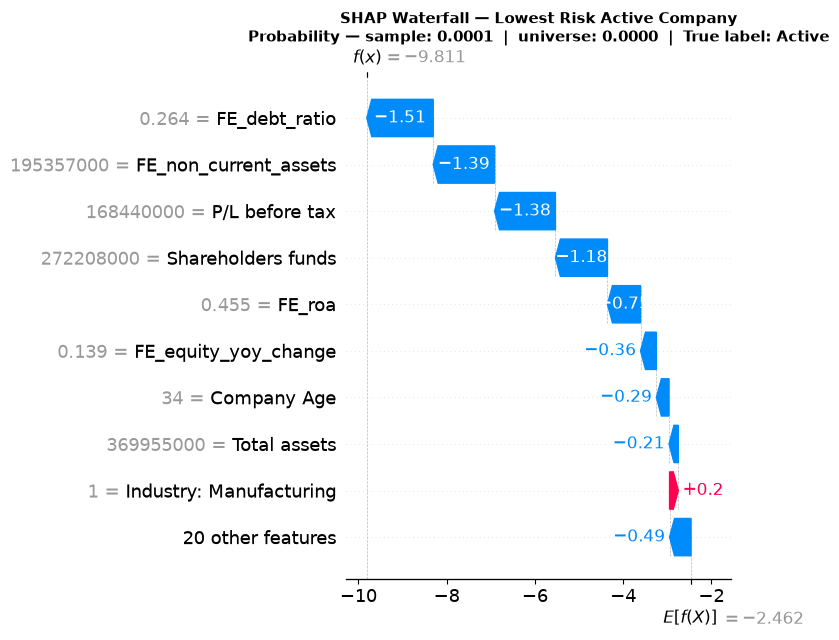


Top 3 features by mean absolute SHAP value:
  1. FE_debt_ratio  (0.8883)
  2. FE_roa  (0.3061)
  3. Current liabilities  (0.2965)


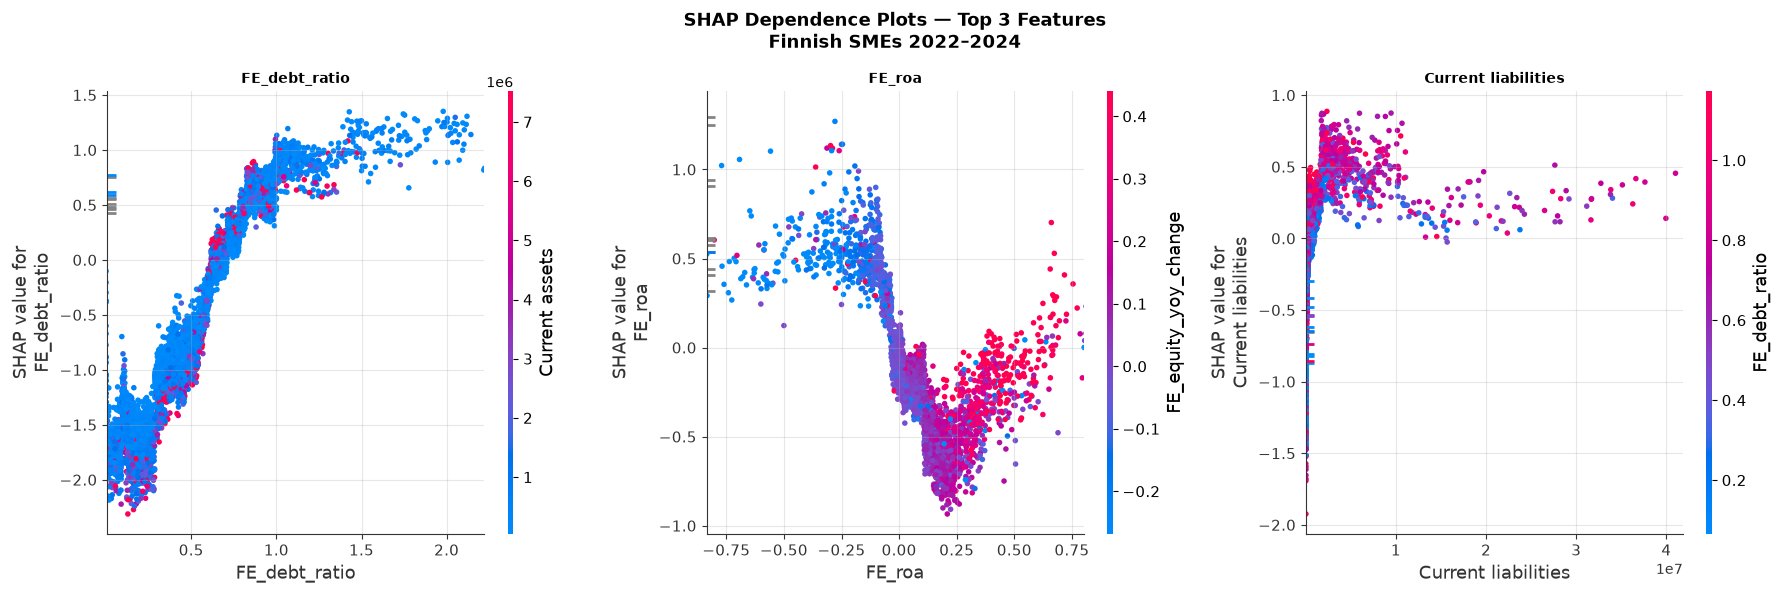


  SHAP Analysis Complete

  Files saved to results/:
    shap_beeswarm.png
    shap_importance_bar.png
    shap_waterfall_bankrupt.png
    shap_waterfall_active.png
    shap_dependence_top3.png


In [10]:
# ── SHAP interpretability ─────────────────────────────────────
# SHAP (SHapley Additive exPlanations) decomposes each
# prediction into the contribution of each feature, based
# on Shapley values from cooperative game theory.
#
# For each company-year observation, SHAP produces a value
# per feature showing:
#   - Magnitude: how much that feature moved the prediction
#   - Direction: whether it pushed toward bankrupt or active
#
# Plots produced:
#   A — Beeswarm summary: feature importance + direction
#   B — Bar plot: mean absolute SHAP values (ranked)
#   C — Waterfall: individual prediction breakdown
#       - one high-risk bankrupt company
#       - one low-risk active company
#   D — Dependence plots for top 3 features
#
# SHAP values are in log-odds at sample level. The universe
# correction is a constant log-odds shift (log of odds_factor),
# so it moves only the base value — contributions are unchanged.

import shap

# Compute SHAP values on full test set
# TreeExplainer is optimised for tree-based models — fast
# and exact (not approximate) for XGBoost
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

print(f"SHAP values computed:")
print(f"  Shape: {shap_values.shape}")
print(f"  (rows × features = {X_test.shape[0]:,} × {X_test.shape[1]})")

# ── A: Beeswarm summary plot ──────────────────────────────────
# Each dot is one observation.
# X axis: SHAP value (positive = pushes toward bankrupt)
# Color:  feature value (red = high, blue = low)
# Features ranked by mean absolute SHAP value (most important top)

plt.figure()   # fresh figure — SHAP draws on the current one
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="dot",
    max_display=20,
    show=False,
)
plt.title(
    'SHAP Beeswarm — Feature Impact on Bankruptcy Prediction\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig("results/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

# ── B: Bar plot — mean absolute SHAP values ───────────────────
# Cleaner summary of overall feature importance.
# Unlike XGBoost built-in importance (which uses gain/frequency),
# SHAP importance is consistent and theoretically grounded.

plt.figure()
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20,
    show=False,
)
plt.title(
    'SHAP Feature Importance — Mean Absolute SHAP Value\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig("results/shap_importance_bar.png", dpi=150, bbox_inches="tight")
plt.show()

# ── C: Waterfall plots — individual predictions ───────────────
# Shows how each feature contributed to one specific prediction.
# Useful for explaining why the model flagged a company.
#
# Select:
#   - highest predicted probability bankrupt company (true positive)
#   - lowest predicted probability active company (true negative)

shap_exp = shap.Explanation(
    values          = shap_values,
    base_values     = explainer.expected_value,
    data            = X_test.values,
    feature_names   = X_test.columns.tolist()
)

# Highest risk bankrupt — most confident correct bankruptcy prediction
bankrupt_idx = np.where(y_test == 1)[0]
highest_risk_idx = bankrupt_idx[np.argmax(y_prob[bankrupt_idx])]

plt.figure()
shap.waterfall_plot(shap_exp[highest_risk_idx], show=False)
plt.title(
    f'SHAP Waterfall — Highest Risk Bankrupt Company\n'
    f'Probability — sample: {y_prob[highest_risk_idx]:.4f}  |  '
    f'universe: {y_prob_universe[highest_risk_idx]:.4f}  |  '
    f'True label: Bankrupt',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig("results/shap_waterfall_bankrupt.png", dpi=150, bbox_inches="tight")
plt.show()

# Lowest risk active — most confident correct active prediction
active_idx = np.where(y_test == 0)[0]
lowest_risk_idx = active_idx[np.argmin(y_prob[active_idx])]

plt.figure()
shap.waterfall_plot(shap_exp[lowest_risk_idx], show=False)
plt.title(
    f'SHAP Waterfall — Lowest Risk Active Company\n'
    f'Probability — sample: {y_prob[lowest_risk_idx]:.4f}  |  '
    f'universe: {y_prob_universe[lowest_risk_idx]:.4f}  |  '
    f'True label: Active',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig("results/shap_waterfall_active.png", dpi=150, bbox_inches="tight")
plt.show()

# ── D: Dependence plots — top 3 features ─────────────────────
# Shows relationship between feature value and SHAP value.
# Reveals non-linear effects and interaction patterns.
# Top 3 features identified by mean absolute SHAP value.
# x-axis limited to the 1st–99th percentile so a few very large
# companies do not squash the rest into one corner (no data is
# removed — the axis just ignores the extremes).

mean_abs_shap = np.abs(shap_values).mean(axis=0)
top3_idx      = np.argsort(mean_abs_shap)[::-1][:3]
top3_features = X_test.columns[top3_idx].tolist()

print(f"\nTop 3 features by mean absolute SHAP value:")
for i, feat in enumerate(top3_features):
    print(f"  {i+1}. {feat}  ({mean_abs_shap[top3_idx[i]]:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'SHAP Dependence Plots — Top 3 Features\n'
    'Finnish SMEs 2022–2024',
    fontsize=13, fontweight='bold'
)

for i, feat in enumerate(top3_features):
    shap.dependence_plot(
        feat,
        shap_values,
        X_test,
        ax=axes[i],
        xmin="percentile(1)",
        xmax="percentile(99)",
        show=False,
    )
    axes[i].set_title(f'{feat}', fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/shap_dependence_top3.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Final summary ─────────────────────────────────────────────
print(f"\n{'='*58}")
print(f"  SHAP Analysis Complete")
print(f"{'='*58}")
print(f"\n  Files saved to results/:")
print(f"    shap_beeswarm.png")
print(f"    shap_importance_bar.png")
print(f"    shap_waterfall_bankrupt.png")
print(f"    shap_waterfall_active.png")
print(f"    shap_dependence_top3.png")